# 01 — Complaint Intelligence Analysis

> **Where are complaint risks concentrated, and what should CX/compliance prioritise first?**

| | |
|---|---|
| **Audience** | CX leadership, compliance, operations |
| **Owner** | CX Complaint Intelligence team |
| **Status** | Reference implementation (portfolio sample) |
| **Last reviewed** | 2026-05-25 |
| **Runtime** | ~20 s on the bundled sample |
| **Reproduces from** | `data/raw/cfpb_sample.csv` |

## Business question

Where are complaint risks concentrated &mdash; by product, issue, company, and time &mdash; and what is the operational priority that follows from the evidence?

## How to read this notebook

1. Section **0** initialises the environment and loads data.
2. Sections **1-N** build the analysis tables and visuals.
3. The **Insights** section is generated from the computed tables &mdash; it does not contain hand-written claims.
4. The **Limitations** section flags known caveats before stakeholders act on the numbers.
5. The **Exports** section persists every table and figure under `reports/notebook/01/` so the output is auditable.


## 0. Setup

This cell:

- locates the project root from wherever the kernel was started;
- applies the shared matplotlib house style and pandas display options;
- creates the artefact directory `reports/notebook/01/`;
- captures the Python and library versions used for this run.


In [1]:
from __future__ import annotations

import warnings
from IPython.display import Markdown, display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cx_complaints.reports.notebook_utils import (
    PALETTE,
    RISK_COLORS,
    concentration_table,
    horizontal_bar,
    kpi_table,
    load_complaints,
    load_pipeline_outputs,
    monthly_summary,
    render_environment,
    save_figure,
    save_table,
    setup_notebook,
    topic_labels,
    write_environment_snapshot,
)

warnings.filterwarnings("ignore", category=FutureWarning)

ctx = setup_notebook("01")
render_environment(ctx)


,field,value
0,python,3.12.11
1,platform,Windows-11-10.0.26200-SP0
2,numpy,2.4.6
3,pandas,2.3.3
4,matplotlib,3.10.9
5,scikit-learn,1.8.0
6,project_root,C:\Users\diogo\work_code\portfolio\cx-complain...
7,notebook_id,01


## 1. Load the prepared complaints dataset

In [2]:
complaints = load_complaints(ctx)
print(f"Rows: {len(complaints):,} | Columns: {len(complaints.columns)}")
complaints[[
    "complaint_id",
    "date_received",
    "product",
    "issue",
    "company",
    "risk_score",
    "risk_level",
]].head()


Rows: 1,000 | Columns: 27


,complaint_id,date_received,product,issue,company,risk_score,risk_level
0,9316329,2024-06-21 12:00:00-05:00,Credit reporting or other personal consumer re...,Incorrect information on your report,Experian Information Solutions Inc.,5.00,high
1,9282035,2024-06-18 12:00:00-05:00,Credit reporting or other personal consumer re...,Problem with a company's investigation into an...,CAPITAL ONE FINANCIAL CORPORATION,3.00,medium
2,9265219,2024-06-14 12:00:00-05:00,Credit reporting or other personal consumer re...,Problem with a company's investigation into an...,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",4.25,medium
3,9333110,2024-06-25 12:00:00-05:00,Credit reporting or other personal consumer re...,Incorrect information on your report,"EQUIFAX, INC.",3.75,medium
4,9357247,2024-06-28 12:00:00-05:00,Credit reporting or other personal consumer re...,Incorrect information on your report,Experian Information Solutions Inc.,3.75,medium


## 2. Headline KPIs

In [3]:
kpis = kpi_table(complaints)
kpis

,metric,value,share_of_total_pct
0,Total complaints,1000,100.00
1,High-risk complaints,136,13.60
2,Medium or high-risk complaints,679,67.90
3,Untimely responses,1,0.10
4,Complaints with narrative,0,0.00


## 3. Concentration analysis (product, issue, company)

Each table is sorted by complaint volume then average risk so the dominant categories surface first. A **high risk share** column shows what share of the category's complaints land in the high-risk band.

In [4]:
top_products = concentration_table(complaints, "product")
top_issues = concentration_table(complaints, "issue")
top_companies = concentration_table(complaints, "company")
top_products

,product,complaints,avg_risk_score,high_risk_share_pct
0,Credit reporting or other personal consumer re...,793,3.58,14.60
1,Debt collection,77,3.81,15.60
2,Credit card,43,2.28,2.30
3,Checking or savings account,40,1.99,0.00
4,Mortgage,13,3.63,15.40
5,Student loan,11,1.91,0.00
6,"Payday loan, title loan, personal loan, or adv...",9,4.11,33.30
7,"Money transfer, virtual currency, or money ser...",7,3.43,28.60
8,Vehicle loan or lease,4,1.81,0.00
9,Prepaid card,2,2.38,0.00


In [5]:
top_issues

,issue,complaints,avg_risk_score,high_risk_share_pct
0,Incorrect information on your report,369,4.46,29.00
1,Improper use of your report,227,2.80,3.10
2,Problem with a company's investigation into an...,185,2.73,1.10
3,Attempts to collect debt not owed,39,4.49,20.50
4,Managing an account,23,2.13,0.00
5,Written notification about debt,21,2.54,0.00
6,"Other features, terms, or problems",11,1.91,0.00
7,Problem with a purchase shown on your statement,9,2.97,0.00
8,Closing an account,9,1.50,0.00
9,Problem with fraud alerts or security freezes,8,4.38,12.50


In [6]:
top_companies

,company,complaints,avg_risk_score,high_risk_share_pct
0,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",285,3.50,12.60
1,"EQUIFAX, INC.",253,3.56,14.20
2,Experian Information Solutions Inc.,230,3.60,14.30
3,"CITIBANK, N.A.",17,2.66,0.00
4,WELLS FARGO & COMPANY,17,2.38,0.00
5,JPMORGAN CHASE & CO.,15,2.00,0.00
6,"BANK OF AMERICA, NATIONAL ASSOCIATION",9,3.56,22.20
7,CAPITAL ONE FINANCIAL CORPORATION,8,2.28,12.50
8,GOLDMAN SACHS BANK USA,7,2.29,0.00
9,Resurgent Capital Services L.P.,6,4.38,16.70


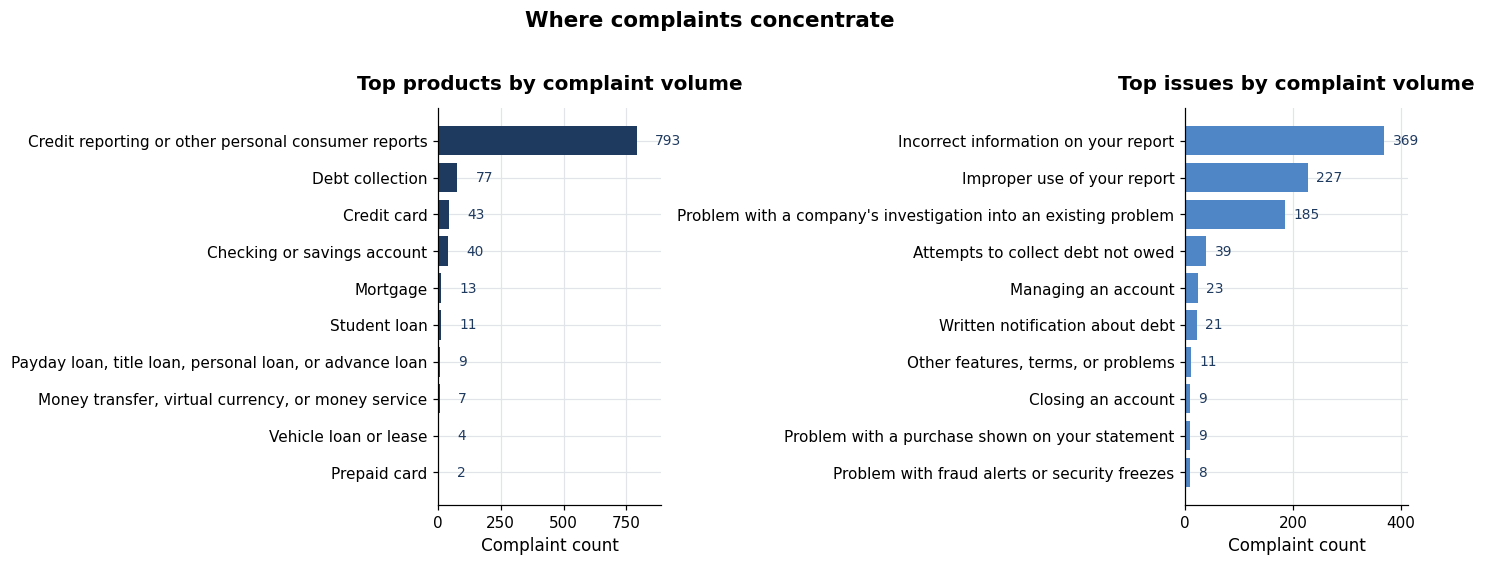

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
horizontal_bar(axes[0], top_products["product"], top_products["complaints"], color=PALETTE["primary"])
axes[0].set_title("Top products by complaint volume")
axes[0].set_xlabel("Complaint count")
horizontal_bar(axes[1], top_issues["issue"], top_issues["complaints"], color=PALETTE["secondary"])
axes[1].set_title("Top issues by complaint volume")
axes[1].set_xlabel("Complaint count")
fig.suptitle("Where complaints concentrate", fontsize=14, fontweight="semibold", y=1.02)
fig.tight_layout()
save_figure(ctx, fig, "concentration_products_issues")
plt.show()

## 4. Trend over time

In [8]:
monthly = monthly_summary(complaints)
monthly

C:\Users\diogo\work_code\portfolio\cx-complaint-intelligence\src\cx_complaints\reports\notebook_utils.py:361: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  dated["month"] = dated[date_column].dt.to_period("M").astype(str)


,month,complaints,avg_risk_score,high_risk_share_pct
0,2024-06,1000,3.45,13.60


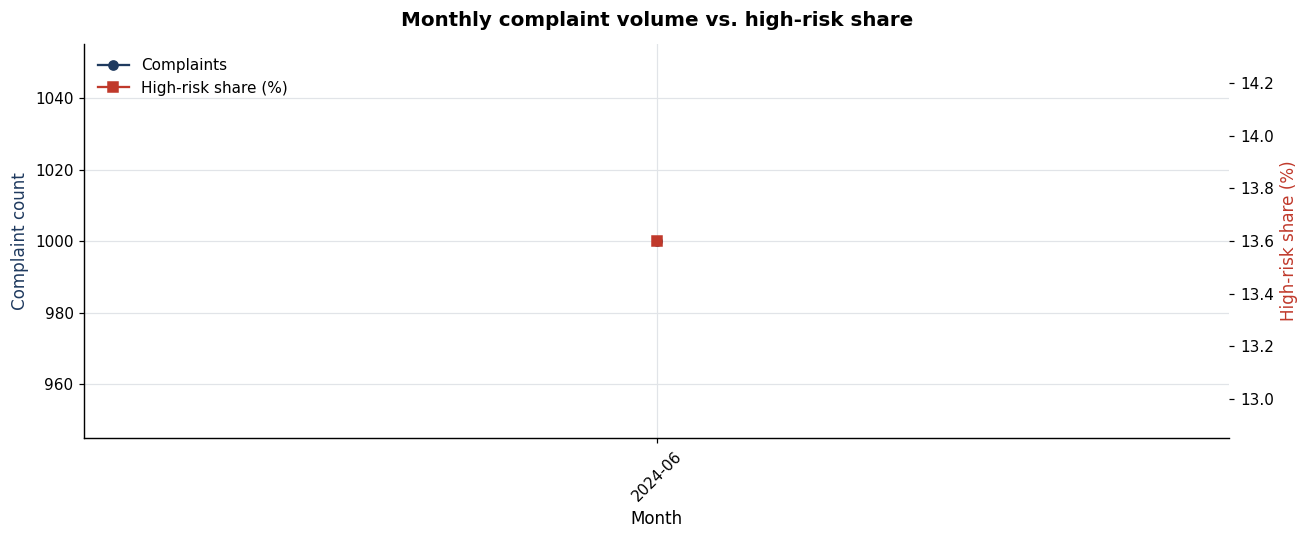

In [9]:
fig, ax_volume = plt.subplots(figsize=(12, 5))
ax_risk = ax_volume.twinx()
ax_risk.grid(False)
ax_volume.plot(
    monthly["month"], monthly["complaints"],
    marker="o", color=PALETTE["primary"], label="Complaints",
)
ax_risk.plot(
    monthly["month"], monthly["high_risk_share_pct"],
    marker="s", color=PALETTE["warning"], label="High-risk share (%)",
)
ax_volume.set_title("Monthly complaint volume vs. high-risk share")
ax_volume.set_xlabel("Month")
ax_volume.set_ylabel("Complaint count", color=PALETTE["primary"])
ax_risk.set_ylabel("High-risk share (%)", color=PALETTE["warning"])
ax_volume.tick_params(axis="x", rotation=45)
lines_a, labels_a = ax_volume.get_legend_handles_labels()
lines_b, labels_b = ax_risk.get_legend_handles_labels()
ax_volume.legend(lines_a + lines_b, labels_a + labels_b, loc="upper left")
fig.tight_layout()
save_figure(ctx, fig, "monthly_volume_vs_risk")
plt.show()

## 5. Response quality and risk distribution

In [10]:
timely_table = (
    complaints.assign(
        timely_clean=complaints["timely"].fillna("Unknown").astype(str).str.title()
    )
    .groupby("timely_clean", as_index=False)
    .agg(
        complaints=("complaint_id", "size"),
        avg_risk_score=("risk_score", "mean"),
        high_risk_share_pct=("risk_level", lambda s: (s == "high").mean() * 100),
    )
    .sort_values("complaints", ascending=False)
)
timely_table["avg_risk_score"] = timely_table["avg_risk_score"].round(2)
timely_table["high_risk_share_pct"] = timely_table["high_risk_share_pct"].round(1)
timely_table

,timely_clean,complaints,avg_risk_score,high_risk_share_pct
1,Yes,999,3.45,13.50
0,No,1,5.75,100.00


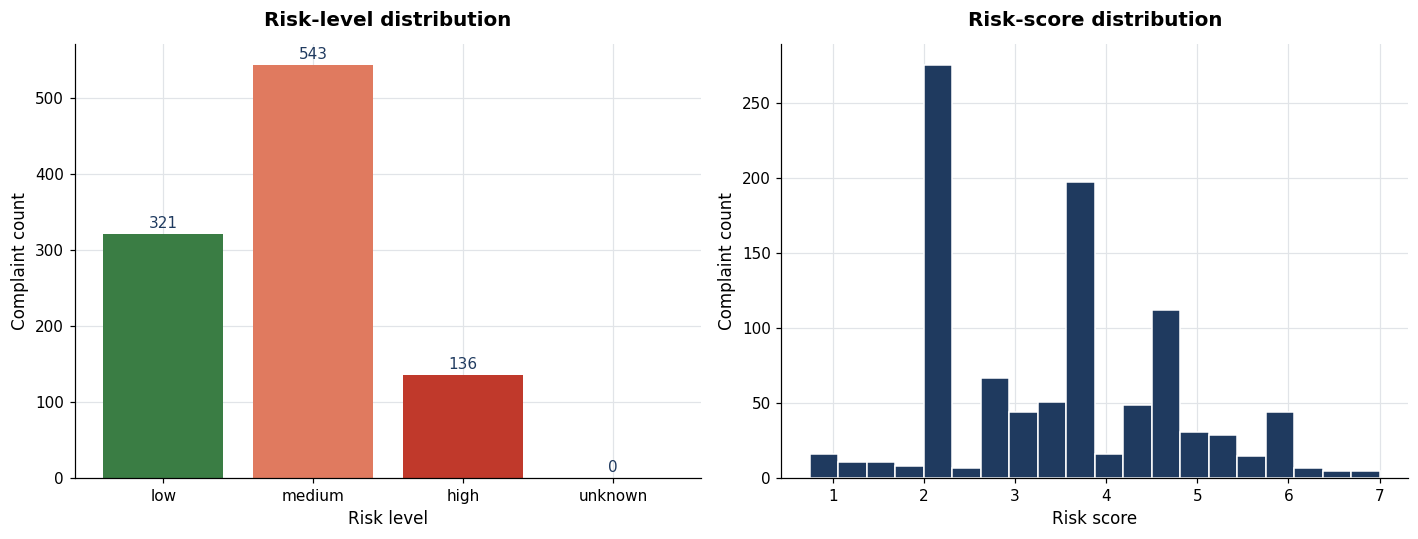

In [11]:
risk_distribution = (
    complaints["risk_level"].fillna("unknown").str.lower().value_counts().reindex(
        ["low", "medium", "high", "unknown"], fill_value=0
    )
)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bars = axes[0].bar(
    risk_distribution.index,
    risk_distribution.values,
    color=[RISK_COLORS[label] for label in risk_distribution.index],
)
for bar in bars:
    axes[0].annotate(
        f"{int(bar.get_height()):,}",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 4), textcoords="offset points",
        ha="center", fontsize=10, color=PALETTE["primary"],
    )
axes[0].set_title("Risk-level distribution")
axes[0].set_xlabel("Risk level")
axes[0].set_ylabel("Complaint count")
axes[1].hist(
    complaints["risk_score"].dropna(), bins=20,
    color=PALETTE["primary"], edgecolor="white",
)
axes[1].set_title("Risk-score distribution")
axes[1].set_xlabel("Risk score")
axes[1].set_ylabel("Complaint count")
fig.tight_layout()
save_figure(ctx, fig, "risk_distribution")
plt.show()

## 6. Insights (generated from the tables above)

In [12]:
top_product = top_products.iloc[0]
top_issue = top_issues.iloc[0]
top_company = top_companies.iloc[0]
peak_month = monthly.sort_values("complaints", ascending=False).iloc[0]
high_share = float(kpis.loc[kpis["metric"] == "High-risk complaints", "share_of_total_pct"].iloc[0])
untimely_share = float(kpis.loc[kpis["metric"] == "Untimely responses", "share_of_total_pct"].iloc[0])

insights = "\n".join([
    f"- **Where**: complaints concentrate in **{top_product['product']}** "
    f"({int(top_product['complaints']):,} records, high-risk share {top_product['high_risk_share_pct']:.1f}%) "
    f"and on the issue **{top_issue['issue']}** ({int(top_issue['complaints']):,} records).",
    f"- **Who**: the highest-volume named company is **{top_company['company']}** "
    f"({int(top_company['complaints']):,} complaints, avg risk {top_company['avg_risk_score']:.2f}).",
    f"- **When**: complaint volume peaked in **{peak_month['month']}** with "
    f"{int(peak_month['complaints']):,} complaints (high-risk share {peak_month['high_risk_share_pct']:.1f}%).",
    f"- **Risk burden**: {high_share:.1f}% of complaints land in the high-risk band; "
    f"{untimely_share:.1f}% are flagged untimely.",
    f"- **Action**: prioritise review of high-risk complaints inside {top_product['product']}, and "
    f"investigate whether the {top_issue['issue']} pattern reflects a single process failure "
    f"or a portfolio-wide pricing/communication issue.",
])
display(Markdown(insights))

- **Where**: complaints concentrate in **Credit reporting or other personal consumer reports** (793 records, high-risk share 14.6%) and on the issue **Incorrect information on your report** (369 records).
- **Who**: the highest-volume named company is **TRANSUNION INTERMEDIATE HOLDINGS, INC.** (285 complaints, avg risk 3.50).
- **When**: complaint volume peaked in **2024-06** with 1,000 complaints (high-risk share 13.6%).
- **Risk burden**: 13.6% of complaints land in the high-risk band; 0.1% are flagged untimely.
- **Action**: prioritise review of high-risk complaints inside Credit reporting or other personal consumer reports, and investigate whether the Incorrect information on your report pattern reflects a single process failure or a portfolio-wide pricing/communication issue.

## Limitations

- The risk score is heuristic, not a legal or regulatory finding. It exists to triage analyst attention.
- CFPB narratives are only published when the consumer consents, so coverage is partial.
- Company-level comparisons mix companies of very different sizes &mdash; always pair them with volume context.
- The sample bundled with this repo is a small subset of the public CFPB dataset and is meant for demonstration, not production decisions.

## Exports

All tables and figures generated above are saved under `reports/notebook/01/`. The environment snapshot is written alongside so a reader can reproduce the run.


In [13]:
save_table(ctx, kpis, "kpis")
save_table(ctx, top_products, "top_products")
save_table(ctx, top_issues, "top_issues")
save_table(ctx, top_companies, "top_companies")
save_table(ctx, monthly, "monthly")
save_table(ctx, timely_table, "timely_response")
write_environment_snapshot(ctx)
sorted(ctx.artefact_dir.iterdir())

[WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/01/concentration_products_issues.png'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/01/environment.json'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/01/kpis.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/01/monthly.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/01/monthly_volume_vs_risk.png'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/01/risk_distribution.png'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/01/timely_response.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/01/top_companies.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-compl